# **Modelamiento de los resultados del NPS UC 2025**

# **Importar paquetes**

In [1]:
import pandas as pd
import os
import sys
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, confusion_matrix
import seaborn as sns

# **Preparación del acceso al Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


# Get the current directory of the notebook
current_dir = os.getcwd()

# Construct the path to the utilidadesML directory (assuming it's in the same directory as the notebook)
utilidadesML_path = os.path.join(current_dir, "drive/MyDrive/Colab Notebooks")

# Add the utilidadesML directory to the Python path
sys.path.append(utilidadesML_path)

import utilidadesML as ml

Mounted at /content/drive


# **Lectura de los datos**

In [3]:
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DATANPS2025.csv', sep=";")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Análisis de correlaciones para Detractores**

**Trabajo solo con las columnas de satisfacción General**

In [25]:
copia = X = estudiantes[['DETRACTOR', 'SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]


**Matriz de correlaciones**

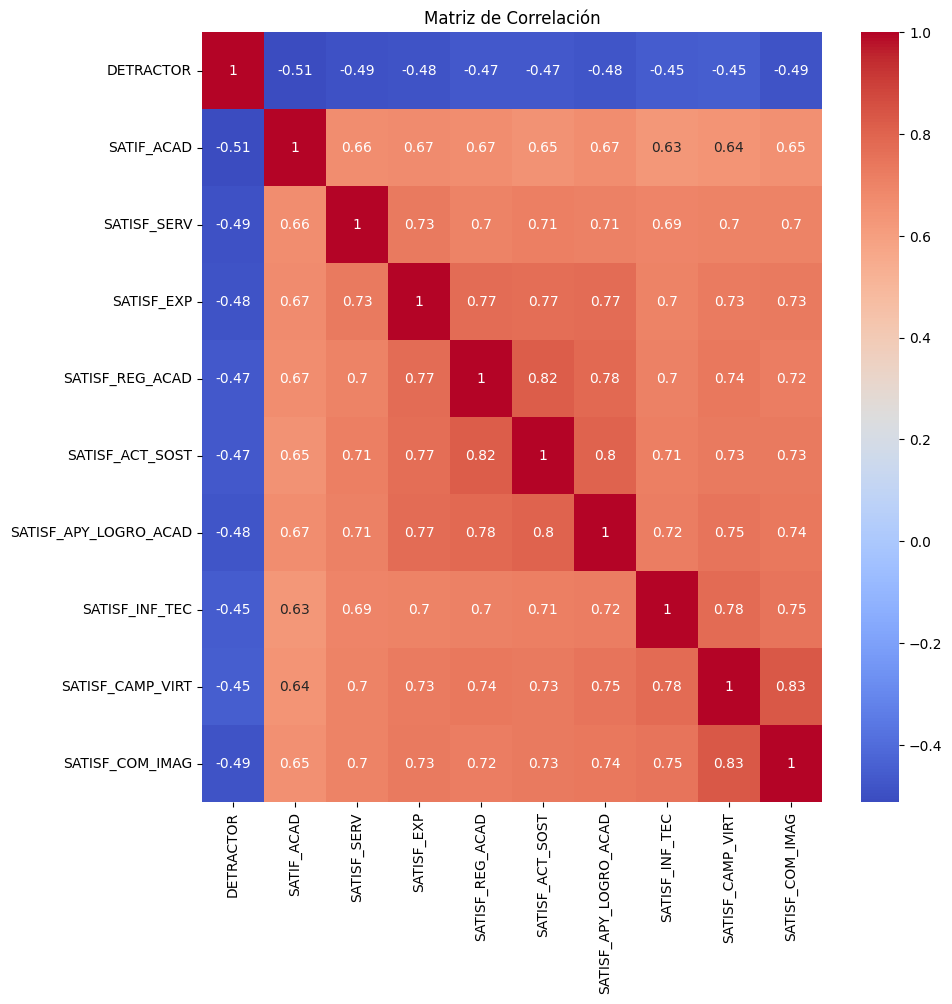

In [26]:
plt.figure(figsize=(10, 10))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

# **Preparación de conjuntos de extrenamiento y testing**

In [27]:
X = estudiantes[['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
y = estudiantes['DETRACTOR']
XCopia = X.copy()

# **Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

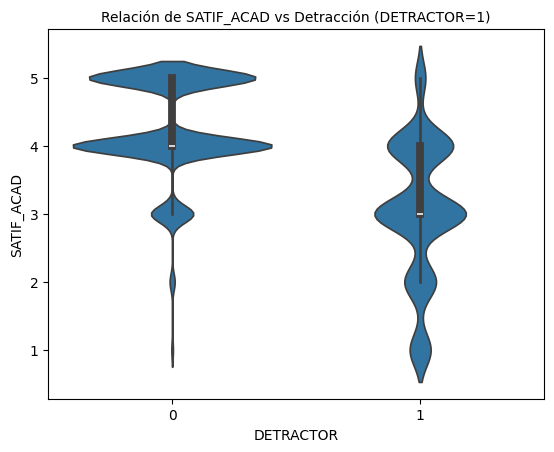

*** Prueba t para SATIF_ACAD ***
Estadístico t: -52.96803
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.265218
1    3.059859
Name: SATIF_ACAD, dtype: float64




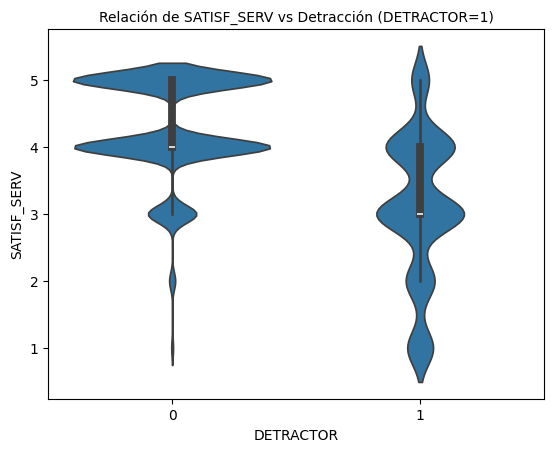

*** Prueba t para SATISF_SERV ***
Estadístico t: -50.04931
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.295423
1    3.103521
Name: SATISF_SERV, dtype: float64




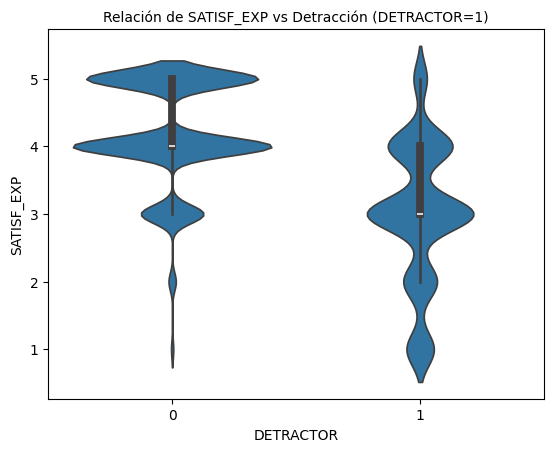

*** Prueba t para SATISF_EXP ***
Estadístico t: -49.02332
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.198644
1    3.011972
Name: SATISF_EXP, dtype: float64




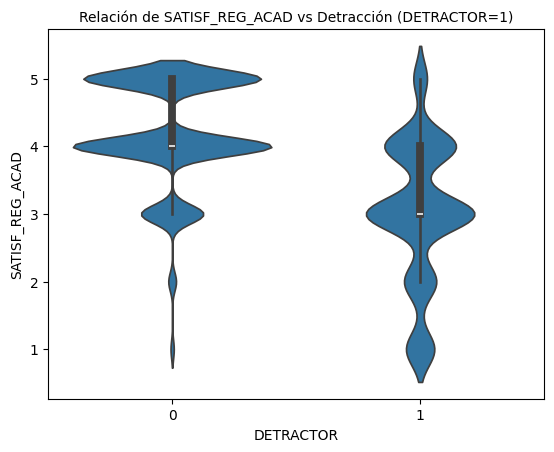

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -47.19341
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.200185
1    3.039437
Name: SATISF_REG_ACAD, dtype: float64




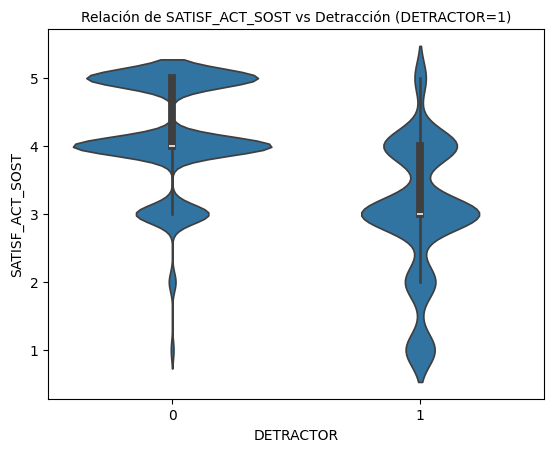

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -46.79372
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.169826
1    3.028873
Name: SATISF_ACT_SOST, dtype: float64




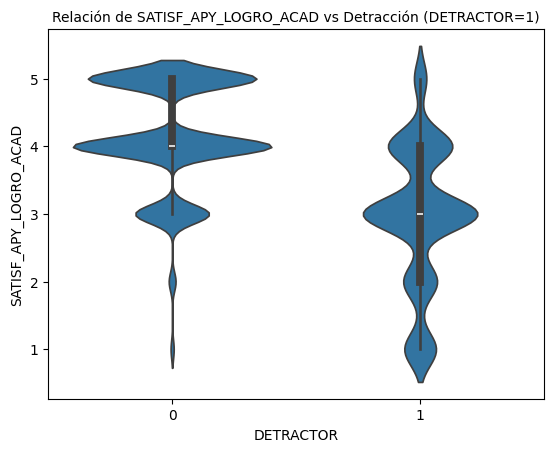

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -48.17843
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.15873
1    2.96831
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




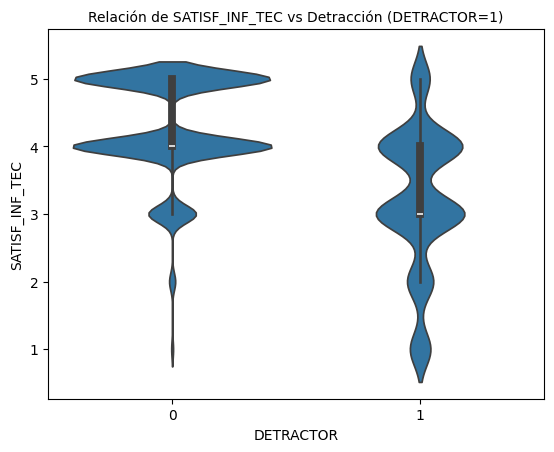

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -45.19964
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.290492
1    3.230986
Name: SATISF_INF_TEC, dtype: float64




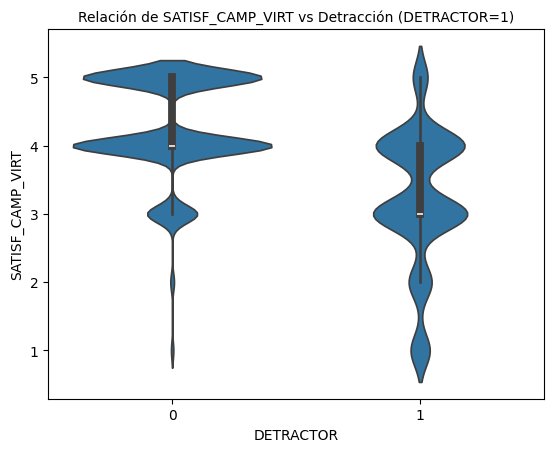

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -44.66085
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.264756
1    3.238028
Name: SATISF_CAMP_VIRT, dtype: float64




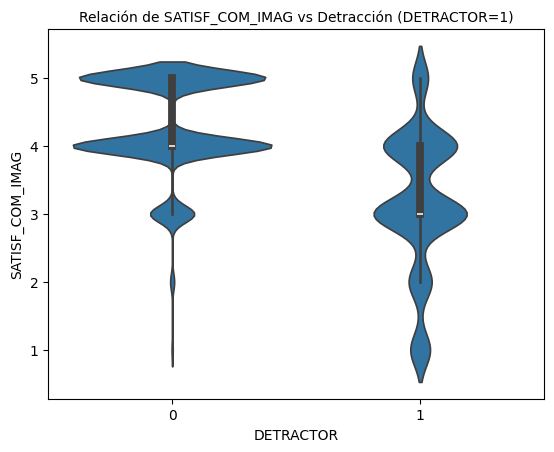

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -49.33390
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.301896
1    3.190141
Name: SATISF_COM_IMAG, dtype: float64




In [29]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes, 'DETRACTOR', column, 1, 0, XCopia)

# **Modelo de Regresión Logística para predecir Detractores**

**Separación de conjuntos de Entrenamiento y Pruebas**

In [30]:
X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

In [31]:
model_balanced = LogisticRegression(solver='liblinear', max_iter=500, random_state=50, class_weight='balanced')

**Entrenamiento del Modelo "Aprendizaje"**

In [32]:
model_balanced.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=500, random_state=50,
                   solver='liblinear')

**Pruebas: Uso de Conjunto de Entrenamiento**

In [33]:
y_pred_balanced = model_balanced.predict(X_test)

**Matriz de Confusión**

Precisión del modelo con class_weight='balanced': 0.803
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      1294
           1       0.47      0.73      0.58       288

    accuracy                           0.80      1582
   macro avg       0.70      0.78      0.72      1582
weighted avg       0.85      0.80      0.82      1582



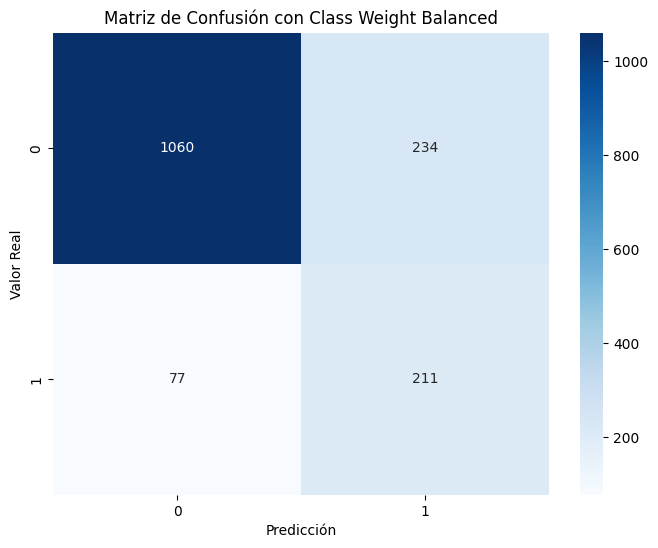

In [34]:
## Cáculo de la Matriz de Confusión
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

### **Análisis de la Importancia de las Variables (`model_balanced`)**

SATIF_ACAD: -0.85
SATISF_SERV: -0.40
SATISF_EXP: -0.19
SATISF_REG_ACAD: -0.10
SATISF_ACT_SOST: -0.17
SATISF_APY_LOGRO_ACAD: -0.19
SATISF_INF_TEC: -0.18
SATISF_CAMP_VIRT: 0.16
SATISF_COM_IMAG: -0.45


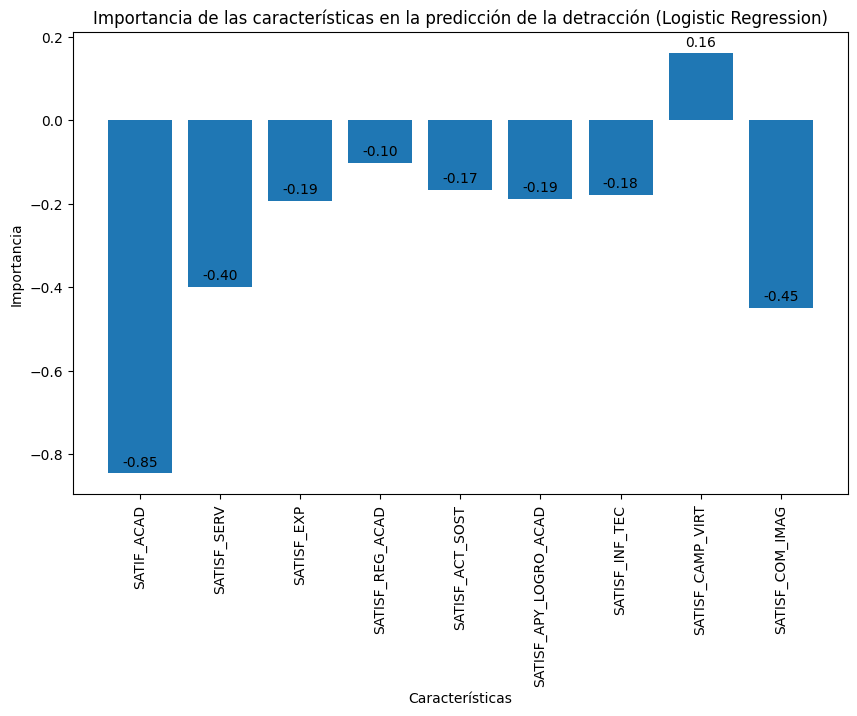

In [35]:
feature_importance = model_balanced.coef_[0]

for i in range(0, len(XCopia.columns)):
    print(f"{XCopia.columns[i]}: {feature_importance[i]:.2f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(XCopia.columns, feature_importance)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en la predicción de la detracción (Logistic Regression)')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.xticks(rotation=90)
plt.show()

### **Análisis SHA: Uso de Deep Learning para saber la importancia de las variables en el resultado del modelo**

In [36]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, shap.kmeans(X_train, 100))
shap_values = explainer.shap_values(X_test)


  0%|          | 0/1582 [00:00<?, ?it/s]

**Gráfico de barras**

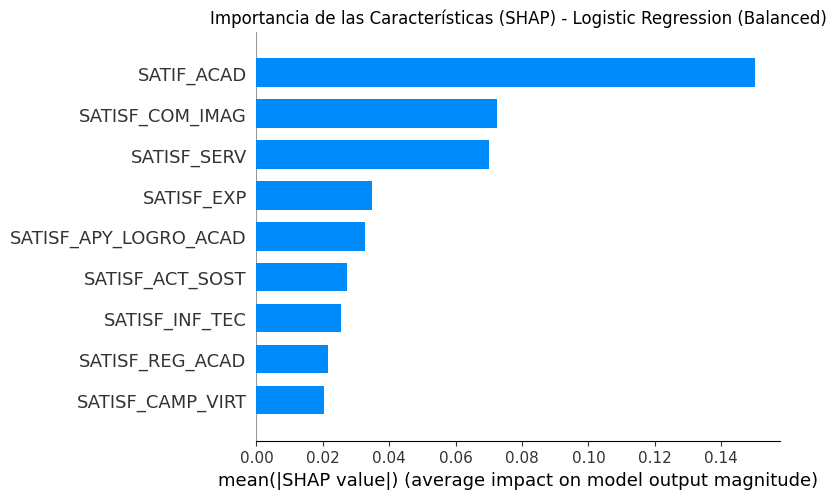

In [37]:
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")

**Gráfico de calor**

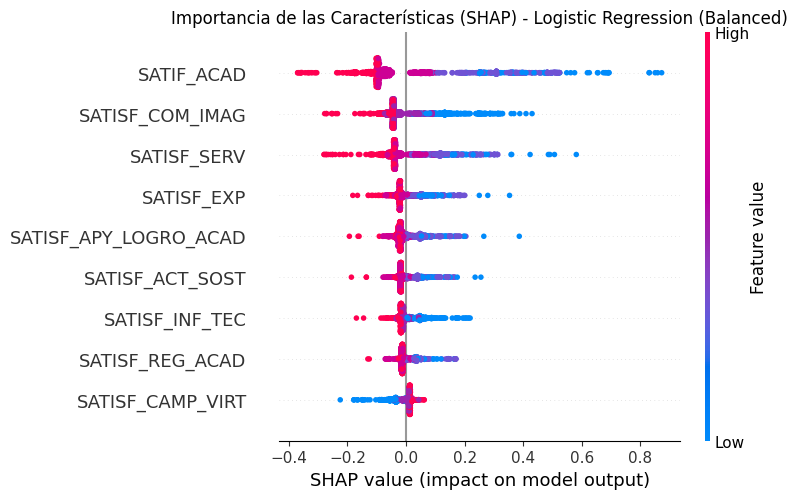

In [38]:
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción lo académico**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

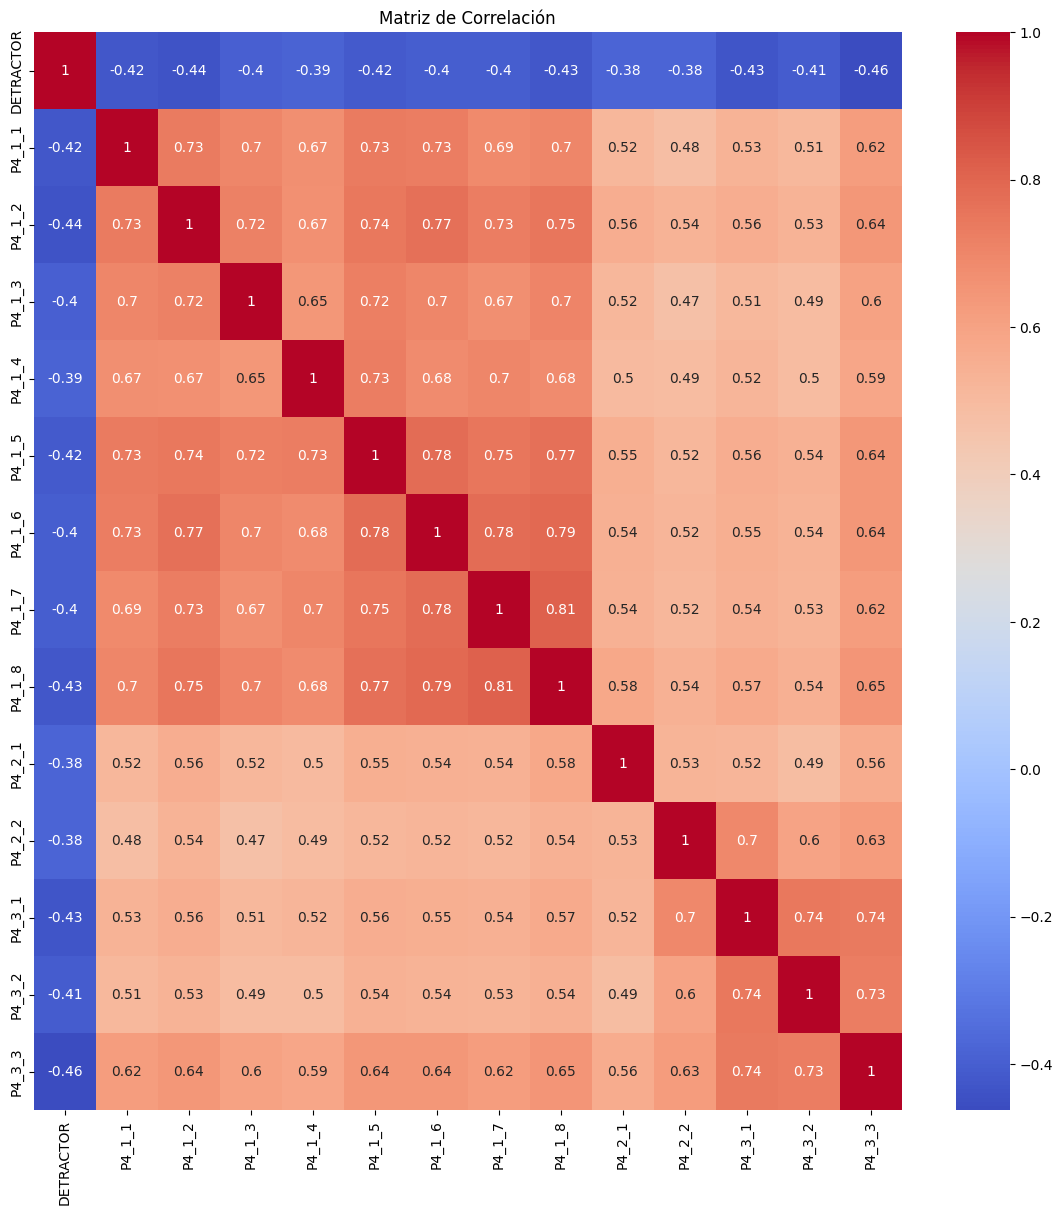

In [40]:
copia = X = estudiantes[['DETRACTOR','P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
plt.figure(figsize=(14, 14))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

**Extracción de as variables de las subcomponnetes de la Satisfacción Académica**

In [41]:
X = estudiantes[['P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
y = estudiantes['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

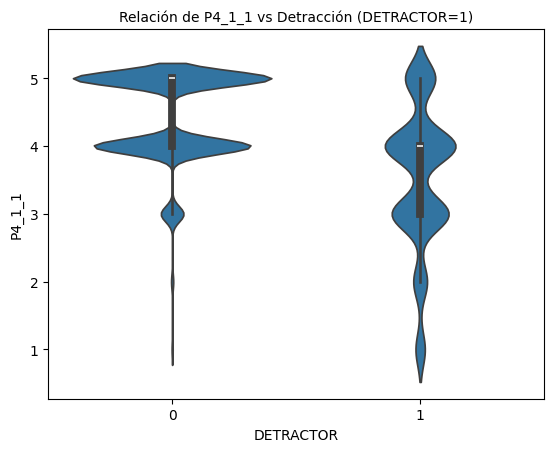

*** Prueba t para P4_1_1 ***
Estadístico t: -41.56553
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.441054
1    3.545775
Name: P4_1_1, dtype: float64




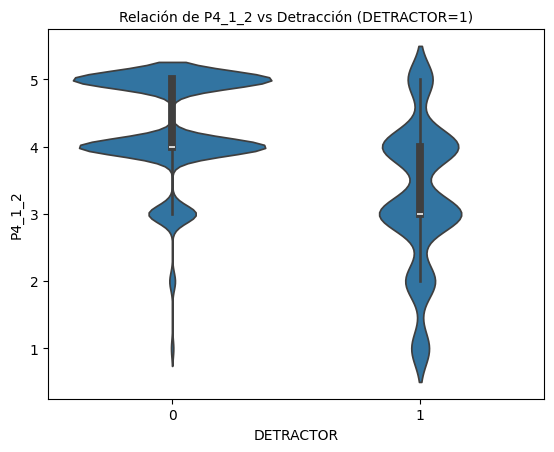

*** Prueba t para P4_1_2 ***
Estadístico t: -43.50389
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.302358
1    3.263380
Name: P4_1_2, dtype: float64




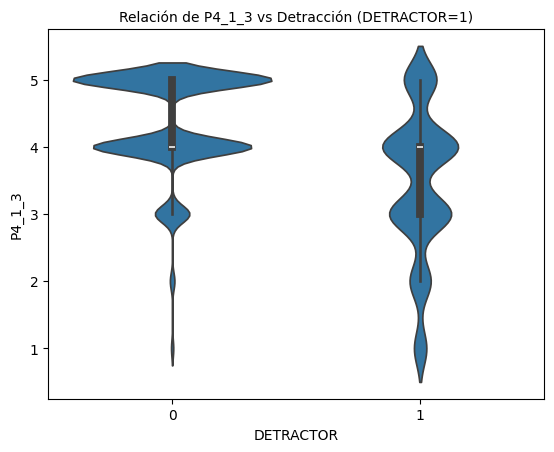

*** Prueba t para P4_1_3 ***
Estadístico t: -38.52166
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.374480
1    3.466901
Name: P4_1_3, dtype: float64




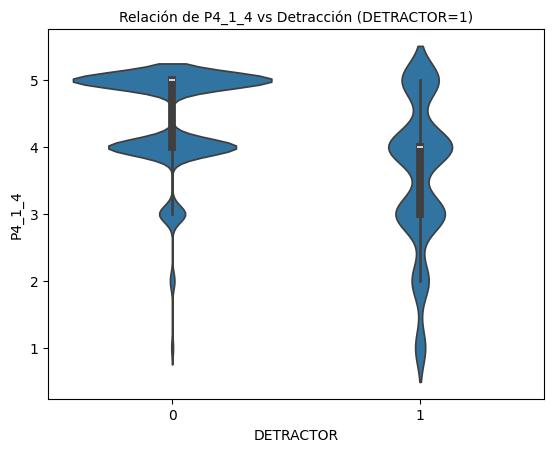

*** Prueba t para P4_1_4 ***
Estadístico t: -37.20391
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.443520
1    3.569718
Name: P4_1_4, dtype: float64




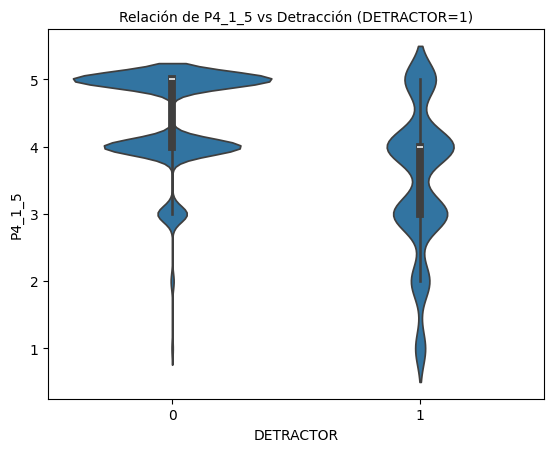

*** Prueba t para P4_1_5 ***
Estadístico t: -40.73887
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.433349
1    3.504930
Name: P4_1_5, dtype: float64




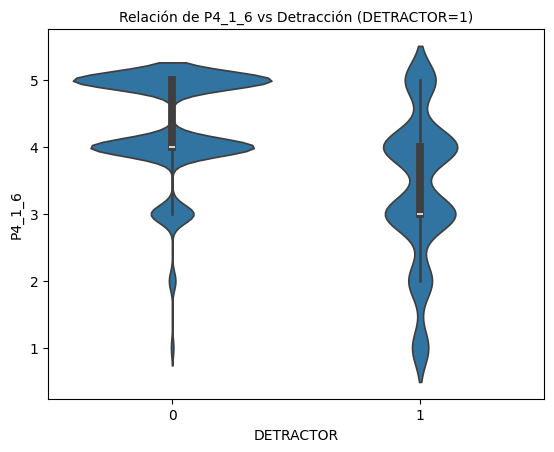

*** Prueba t para P4_1_6 ***
Estadístico t: -39.14719
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.327477
1    3.369718
Name: P4_1_6, dtype: float64




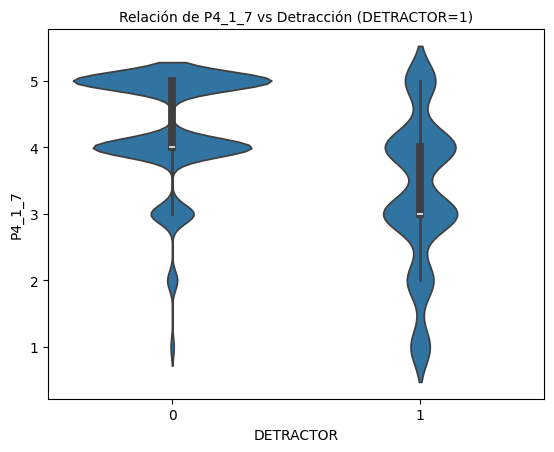

*** Prueba t para P4_1_7 ***
Estadístico t: -39.30739
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.304669
1    3.299296
Name: P4_1_7, dtype: float64




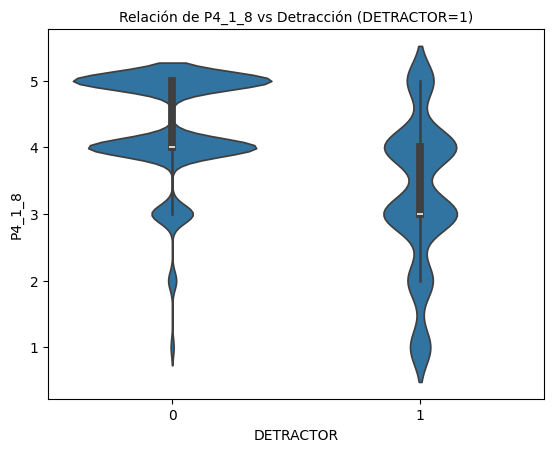

*** Prueba t para P4_1_8 ***
Estadístico t: -41.78359
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.314995
1    3.273944
Name: P4_1_8, dtype: float64




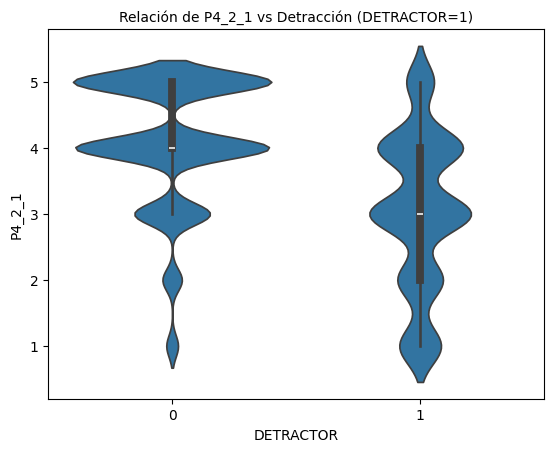

*** Prueba t para P4_2_1 ***
Estadístico t: -36.37483
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.097550
1    3.039437
Name: P4_2_1, dtype: float64




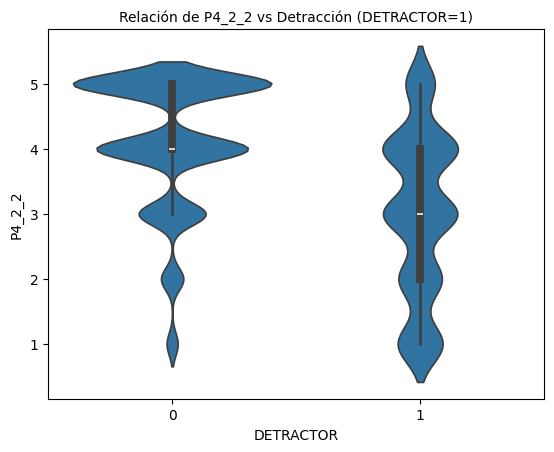

*** Prueba t para P4_2_2 ***
Estadístico t: -36.42484
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.118816
1    3.002113
Name: P4_2_2, dtype: float64




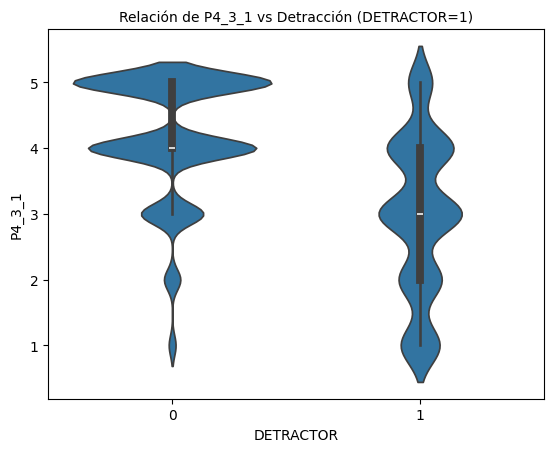

*** Prueba t para P4_3_1 ***
Estadístico t: -42.79751
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.184158
1    2.975352
Name: P4_3_1, dtype: float64




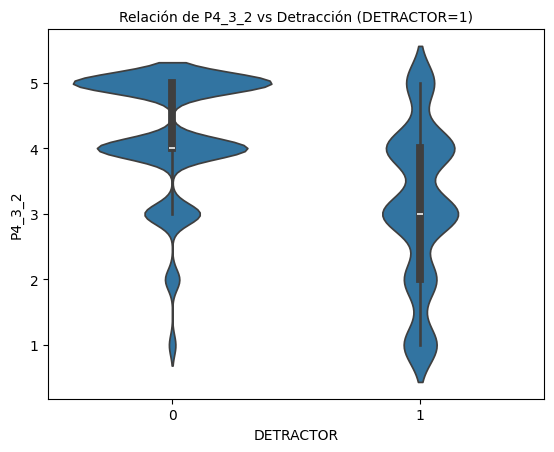

*** Prueba t para P4_3_2 ***
Estadístico t: -39.48742
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.224534
1    3.109155
Name: P4_3_2, dtype: float64




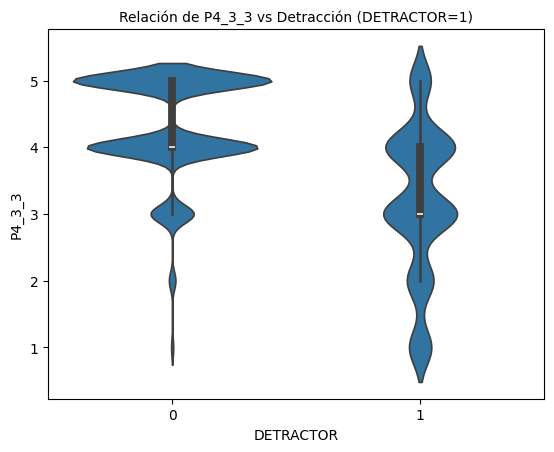

*** Prueba t para P4_3_3 ***
Estadístico t: -46.38537
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.322700
1    3.191549
Name: P4_3_3, dtype: float64




In [43]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes, 'DETRACTOR', column, 1, 0, XCopia)

**Configuración del Modelo**

Precisión del modelo con class_weight='balanced': 0.772
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.93      0.78      0.85      1294
           1       0.43      0.72      0.54       288

    accuracy                           0.77      1582
   macro avg       0.68      0.75      0.69      1582
weighted avg       0.84      0.77      0.79      1582



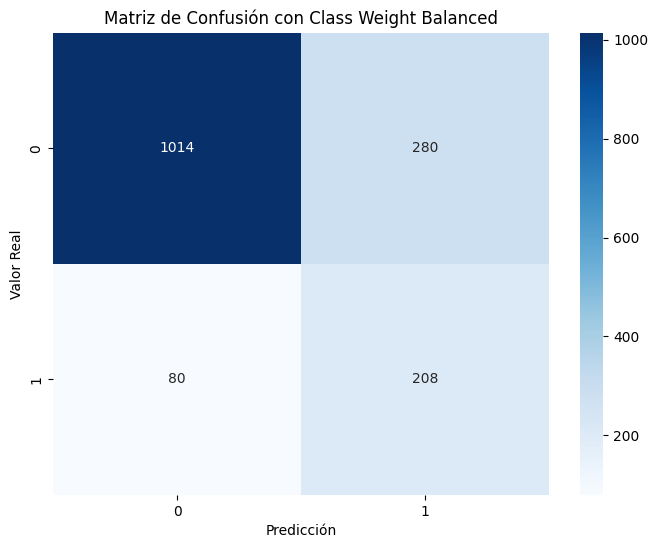

In [44]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.2, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**4.1.1 CONOCIMIENTO Y DOMINIO DE LA ASIGNATURA POR PARTE DEL DOCENTE**

**4.1.8 EL SEGUIMIENTO DEL DESEMPEÑO DEL ESTUDIANTE ACOMPAÑADO DE RETROALIMENTACIÓN CONSTRUCTIVA SOBRE TRABAJOS, PROYECTOS Y ENTREGABLES**

**4.3.1 FLEXIBILIDAD PARA LA ELECCIÓN DE ASIGNATURAS DEL PLAN DE ESTUDIOS**

**4.2.2 LOS HORARIOS DE CLASE SON ADECUADOS Y SE AJUSTAN A LA DISPONIBILIDAD Y REQUERIMIENTOS DE LOS ESTUDIANTES**

  0%|          | 0/1582 [00:00<?, ?it/s]

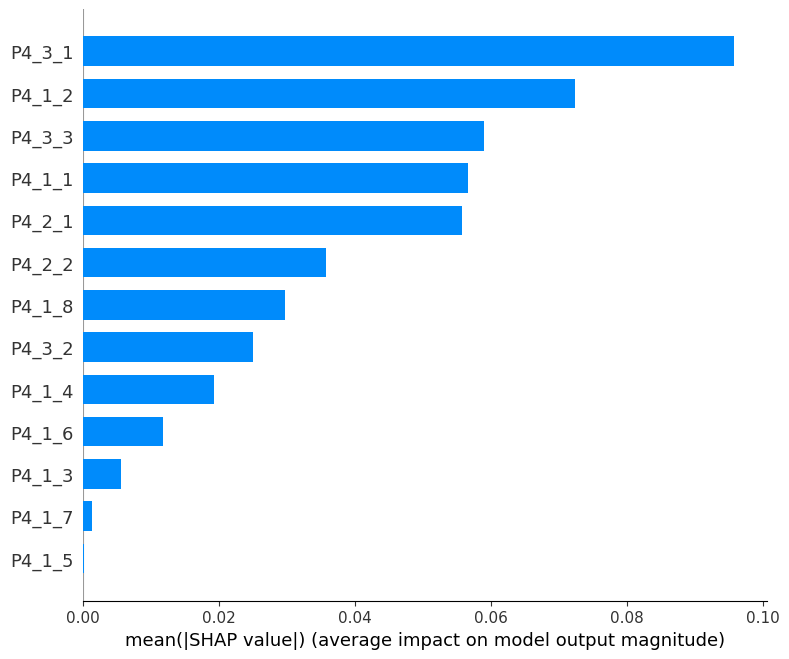

In [45]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, shap.kmeans(X_train, 100))
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")

**Gráfico de calor:**

 **Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

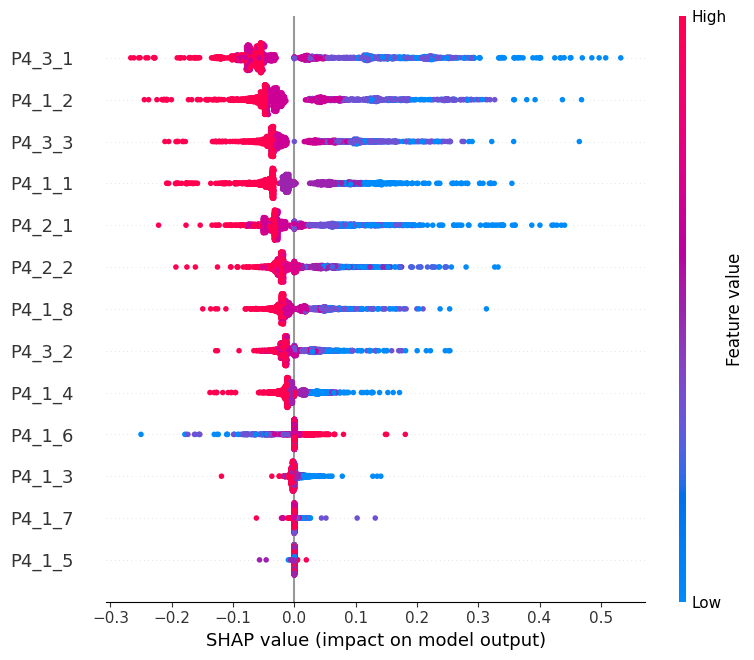

In [46]:
shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción con la Imagen y Comunicación de la universidad**

**P26. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON CADA UNO DE LOS ASPECTOS DE LA COMUNICACIÓN E IMAGEN   DE LA UNIVERSIDAD CONTINENTAL?**

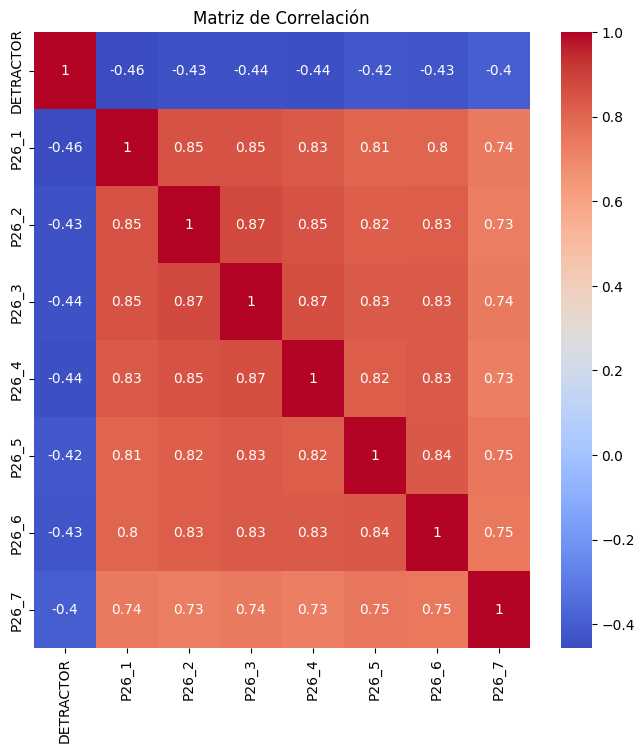

In [48]:
copia = X = estudiantes[['DETRACTOR','P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
plt.figure(figsize=(8, 8))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [49]:
X = estudiantes[['P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
y = estudiantes['DETRACTOR']
XCopia = X.copy()

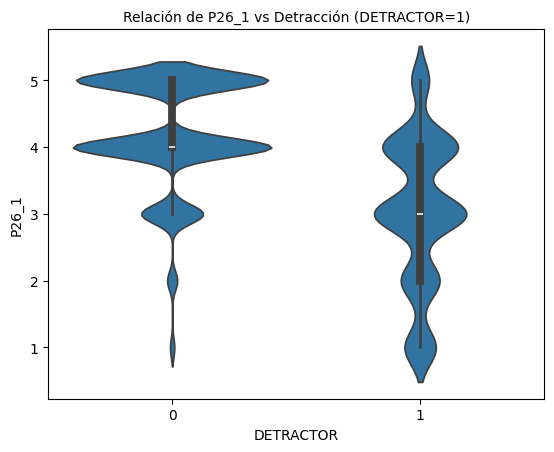

*** Prueba t para P26_1 ***
Estadístico t: -45.66727
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.208353
1    3.037324
Name: P26_1, dtype: float64




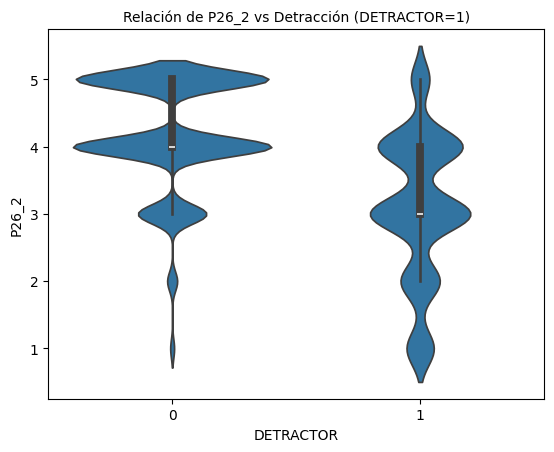

*** Prueba t para P26_2 ***
Estadístico t: -42.91051
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.195099
1    3.104225
Name: P26_2, dtype: float64




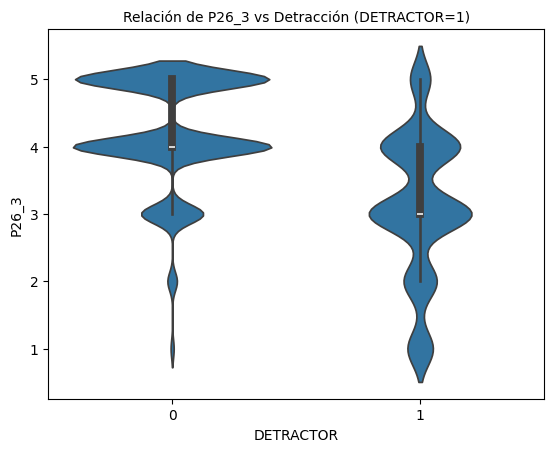

*** Prueba t para P26_3 ***
Estadístico t: -43.40628
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.221298
1    3.139437
Name: P26_3, dtype: float64




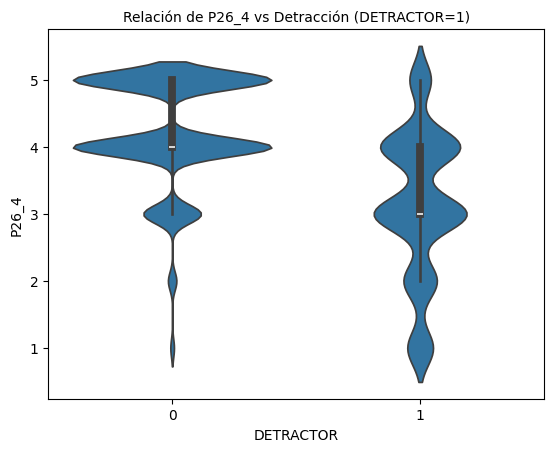

*** Prueba t para P26_4 ***
Estadístico t: -43.66659
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.241486
1    3.150000
Name: P26_4, dtype: float64




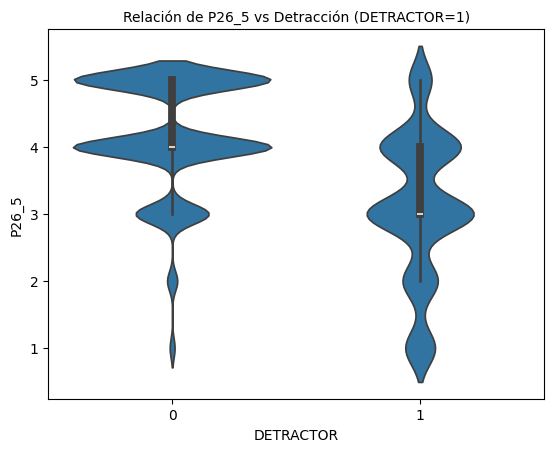

*** Prueba t para P26_5 ***
Estadístico t: -41.15081
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.183387
1    3.116197
Name: P26_5, dtype: float64




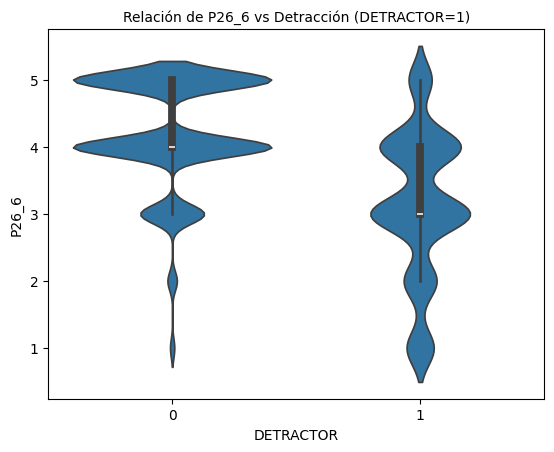

*** Prueba t para P26_6 ***
Estadístico t: -41.76195
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.216212
1    3.152113
Name: P26_6, dtype: float64




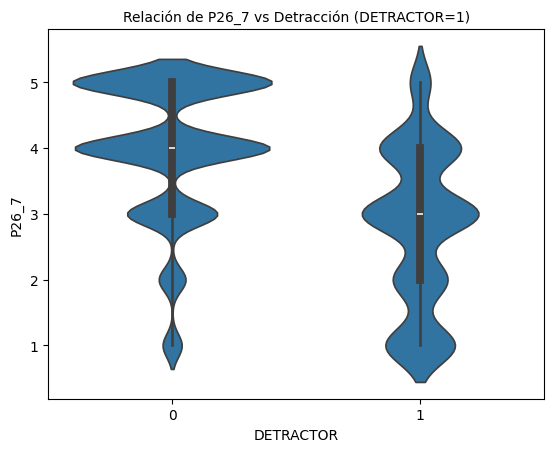

*** Prueba t para P26_7 ***
Estadístico t: -38.65784
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.997380
1    2.792958
Name: P26_7, dtype: float64




In [50]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.757
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.92      0.77      0.84      1294
           1       0.40      0.69      0.51       288

    accuracy                           0.76      1582
   macro avg       0.66      0.73      0.67      1582
weighted avg       0.82      0.76      0.78      1582



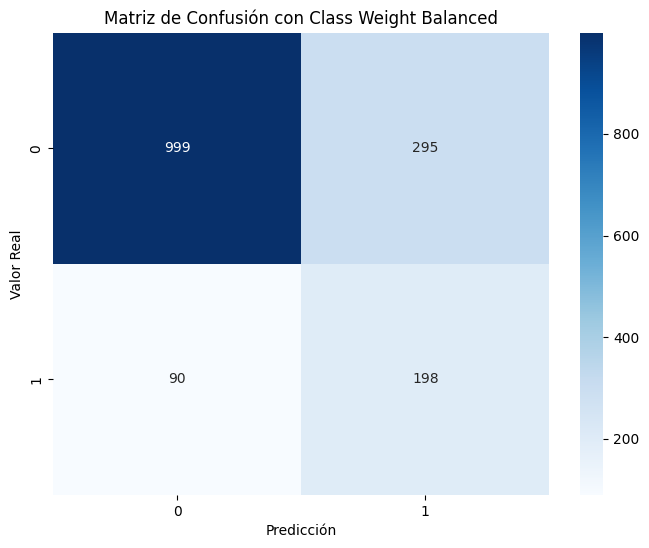

In [51]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.2, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**26.1 COMUNICACIÓN OPORTUNA A LOS ESTUDIANTES DE LOS BENEFICIOS, ESTÍMULOS Y NORMATIVAS DE LA UNIVERSIDAD**

**26.7 MONTO DE LA PENSIÓN**

**26.4 MEDIOS UTILIZADOS POR LA UNIVERSIDAD PARA LA COMUNICACIÓN CON EL ESTUDIANTE SON ADECUADAS**


  0%|          | 0/1582 [00:00<?, ?it/s]

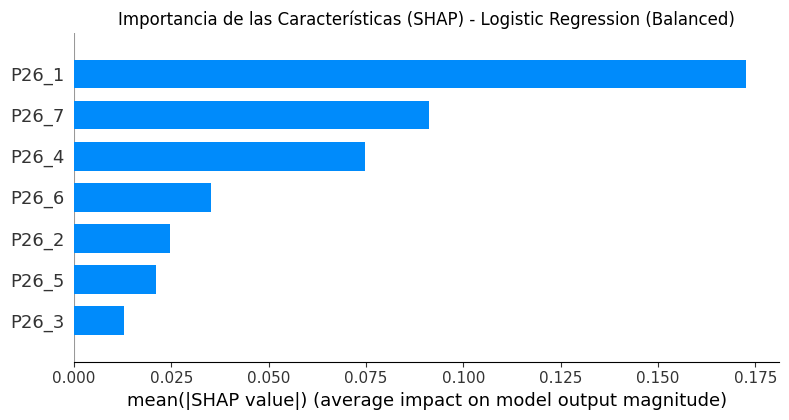

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")


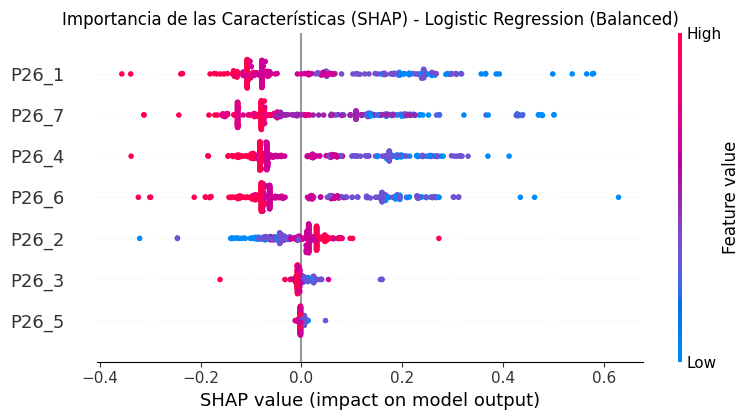

In [ ]:

plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# Task
Import necessary libraries for building and training a neural network, including TensorFlow, Keras layers, and StandardScaler for feature scaling, and to_categorical for target variable encoding. Then, preprocess the `y` target variable (REC_TIPO with values -1, 0, 1) by mapping it to 0-indexed values (0, 1, 2) and applying one-hot encoding. Scale the `XCopia` features using StandardScaler. Split the scaled features and the one-hot encoded target variable into training and testing sets. Define a sequential Keras model with an input layer matching the number of features in `XCopia`, at least one dense hidden layer with 'relu' activation, and an output layer with 3 neurons and 'softmax' activation. Compile the model using the 'adam' optimizer, 'categorical_crossentropy' loss, and 'accuracy' metric. Train the neural network model using the preprocessed training data, and then evaluate its performance by making predictions on the test set, calculating accuracy, and generating a classification report. Finally, visualize the confusion matrix for the neural network model's predictions and summarize the model's configuration and performance.

## Import Deep Learning Libraries

### Subtask:
Import necessary libraries for building and training a neural network, including TensorFlow, Keras layers, and StandardScaler for feature scaling, and to_categorical for target variable encoding.


**Reasoning**:
The subtask requires importing specific deep learning libraries. I will use a code block to import TensorFlow, StandardScaler, and to_categorical as specified in the instructions.



In [19]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical

**Reasoning**:
I will preprocess the target variable `y` by mapping its values (-1, 0, 1) to 0-indexed values (0, 1, 2) and then applying one-hot encoding. Simultaneously, I will scale the `XCopia` features using `StandardScaler` to ensure that all features contribute equally to the model's training. Finally, I will split these preprocessed data into training and testing sets as required by the subtask.



In [20]:
y_mapped = y.map({-1: 0, 0: 1, 1: 2})
y_one_hot = to_categorical(y_mapped)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(XCopia)

X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(X_scaled, y_one_hot, test_size=0.20, random_state=42)

**Reasoning**:
I will define a sequential Keras model with an input layer, at least one dense hidden layer with 'relu' activation, and an output layer with 3 neurons and 'softmax' activation. Then, I will compile the model using the 'adam' optimizer, 'categorical_crossentropy' loss, and 'accuracy' metric.



In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Define the neural network model
model_nn = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_nn.shape[1],)), # Input layer and first hidden layer
    Dense(32, activation='relu'), # Additional hidden layer
    Dense(3, activation='softmax') # Output layer for 3 classes
])

# Compile the model
model_nn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Neural network model defined and compiled.")
model_nn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Neural network model defined and compiled.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,819 (11.01 KB)

 Trainable params: 2,819 (11.01 KB)

 Non-trainable params: 0 (0.00 B)

**Reasoning**:
The next logical step is to train the neural network model using the preprocessed training data and then evaluate its performance on the test set. This involves fitting the model, making predictions, calculating accuracy, generating a classification report, and visualizing the confusion matrix.



Training the neural network model...
Epoch 1/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7034 - loss: 0.6750 - val_accuracy: 0.6809 - val_loss: 0.7405
Epoch 2/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7113 - loss: 0.6498 - val_accuracy: 0.6746 - val_loss: 0.7466
Epoch 3/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7021 - loss: 0.6605 - val_accuracy: 0.6840 - val_loss: 0.7388
Epoch 4/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7197 - loss: 0.6340 - val_accuracy: 0.6801 - val_loss: 0.7460
Epoch 5/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7040 - loss: 0.6579 - val_accuracy: 0.6825 - val_loss: 0.7433
Epoch 6/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7109 - loss: 0.6552 - val_accuracy: 0.6754 - val_loss: 0.7553
Epoch 7/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7166 - loss: 0.6449 - val_accuracy: 0.6769 - val_loss: 0.7468
Epoch 8/50
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7

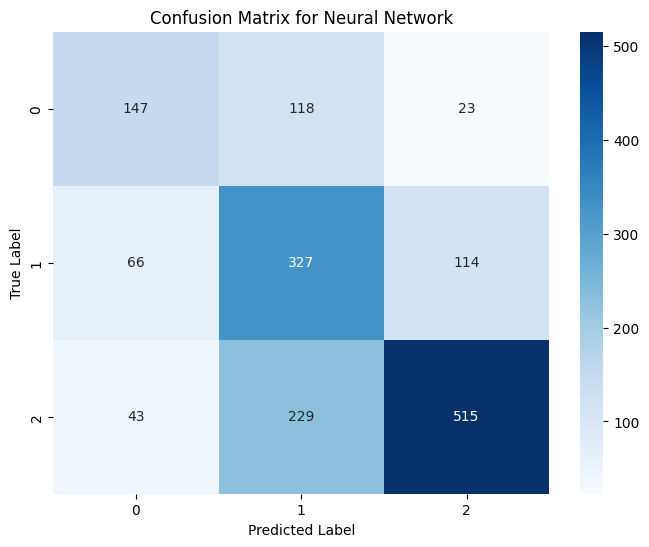

In [24]:
print("Training the neural network model...")
history = model_nn.fit(X_train_nn, y_train_nn, epochs=50, batch_size=32, validation_split=0.2, verbose=1)
print("Neural network model trained.")

# Evaluate the model
loss, accuracy = model_nn.evaluate(X_test_nn, y_test_nn, verbose=0)
print(f"\nNeural Network Model Accuracy: {accuracy:.3f}")

y_pred_nn_prob = model_nn.predict(X_test_nn)
y_pred_nn = tf.argmax(y_pred_nn_prob, axis=1)
y_test_labels = tf.argmax(y_test_nn, axis=1)

# Classification Report
report_nn = classification_report(y_test_labels, y_pred_nn)
print(f"\nClassification Report for Neural Network:\n{report_nn}")

# Confusion Matrix
cm_nn = confusion_matrix(y_test_labels, y_pred_nn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Neural Network')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


## Final Task

### Subtask:
Summarize the neural network model's configuration and performance, highlighting key insights from the evaluation and confusion matrix.


## Summary:

### Data Analysis Key Findings

*   The neural network model was configured as a Sequential Keras model with an input layer, two dense hidden layers (64 and 32 neurons, both using 'relu' activation), and an output layer with 3 neurons using 'softmax' activation.
*   The model was compiled using the 'adam' optimizer, 'categorical_crossentropy' loss function, and 'accuracy' as the metric.
*   After training for 50 epochs, the neural network achieved an overall accuracy of **0.645** on the test set.
*   Detailed performance by class showed varying results:
    *   **Class 0**: Achieved a precision of 0.60, recall of 0.54, and an F1-score of 0.57.
    *   **Class 1**: Showed a precision of 0.51, recall of 0.63, and an F1-score of 0.56.
    *   **Class 2**: Demonstrated the strongest performance with a precision of 0.78, recall of 0.69, and an F1-score of 0.73.
*   The confusion matrix visually represented the model's predictions, indicating how well each class was identified and where misclassifications occurred.

### Insights or Next Steps

*   The model shows potential for improvement, especially for Class 0 and Class 1, which have lower precision and F1-scores compared to Class 2. Future work could focus on exploring techniques like class weighting, data augmentation, or more advanced architectures to balance performance across all classes.
*   Further hyperparameter tuning (e.g., number of epochs, batch size, learning rate, number of hidden layers, or neurons per layer) could potentially enhance the model's overall accuracy and reduce misclassifications.
